# 地磁场测量实验 —— 磁阻传感器磁电转换特性的测量

**原始数据**：表 11-1，励磁电流 $I$、对应磁感应强度 $B$ 与传感器输出电压 $U$（13 个点，$B=-6\sim6$ Gs）。

**物理原理**

1. 磁阻传感器内部是四个磁阻元件构成的惠斯通电桥。外加磁场使元件阻值改变，桥臂失衡，
   输出差分电压。在弱场范围内，不平衡电压近似与磁感应强度成正比：
   $$U = K\,B + U_0$$
   其中 $K$ 为磁电转换灵敏度，$U_0$ 为零点残余电压（失调 + 本底场）。
2. 表 11-1 中螺线管励磁电流 $I$ 与产生的 $B$ 一一对应（$B$ 按线圈常数标定），
   因此直接作 $U$–$B$ 图并作最小二乘直线拟合，由斜率得到灵敏度、由截距得到零点。

**处理思路**

1. 13 个数据点原样作图（黑色实心方块），不作平滑、不作镜像对称化。
2. 拟合 $U = a + b\,B$，实算斜率、截距的标准误差与 $\mathrm{Adj.}\ R^2$。
3. 用正、负半轴读数的对称性检查磁滞与零点偏移，作为误差来源的依据。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

# 注意：字体名必须直接写进 font.family 列表，matplotlib 才会逐字回退
rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据（表 11-1，按 I 从小到大重排） ----------
I_mA = np.array([-300, -250, -200, -150, -100, -50, 0,  50, 100, 150,  200,  250,  300], dtype=float)  # 励磁电流 I/mA
B_Gs = np.array([  -6,   -5,   -4,   -3,   -2,  -1, 0,   1,   2,   3,    4,    5,    6], dtype=float)  # 磁感应强度 B/Gs
U_V  = np.array([-1.464, -1.242, -1.008, -0.766, -0.518, -0.263, 0.002,
                   0.261,  0.518,  0.774,  1.024,  1.266,  1.500])                                     # 输出电压 U/V

# ---------- 数据处理：最小二乘 U = a + b·B ----------
n      = len(B_Gs)
b, a   = np.polyfit(B_Gs, U_V, 1)          # 拟合 U = a + b·B
U_hat  = a + b * B_Gs
ss_res = np.sum((U_V - U_hat) ** 2)
ss_tot = np.sum((U_V - U_V.mean()) ** 2)
r2     = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - 2)

sxx  = np.sum((B_Gs - B_Gs.mean()) ** 2)
s    = np.sqrt(ss_res / (n - 2))
se_b = s / np.sqrt(sxx)                                 # 斜率标准误差
se_a = s * np.sqrt(1 / n + B_Gs.mean() ** 2 / sxx)      # 截距标准误差
r_coef = np.corrcoef(B_Gs, U_V)[0, 1]                   # Pearson r

df = pd.DataFrame({
    '励磁电流 I/(mA)':   I_mA.astype(int),
    '磁感应强度 B/(Gs)': B_Gs.astype(int),
    '输出电压 U/(V)':    U_V,
    '拟合值 Û/(V)':      U_hat.round(4),
    '残差 U−Û/(V)':      (U_V - U_hat).round(4),
})
display(df)

print(f'拟合方程 : U = {a:.4f} + {b:.4f} · B   (V, Gs)')
print(f'斜率 b   = {b:.4f} ± {se_b:.4f}  V/Gs   → K ≈ {b*1e4:.0f} V/T = {b*1e3:.1f} mV/Gs')
print(f'截距 a   = {a:.4f} ± {se_a:.4f}  V')
print(f'R² = {r2:.5f}    Adj. R² = {adj_r2:.5f}    Pearson r = {r_coef:.5f}')
print(f'最大残差 = {np.abs(U_V - U_hat).max():.4f} V，满量程 {U_V.max()-U_V.min():.3f} V')

# 正、负半轴分开拟合，检查对称性（磁滞/失调）
for lab, m in [('正向(B≥0)', B_Gs >= 0), ('反向(B≤0)', B_Gs <= 0)]:
    bb, aa = np.polyfit(B_Gs[m], U_V[m], 1)
    print(f'{lab}: 斜率 {bb:.4f} V/Gs，截距 {aa:+.4f} V')
pairs = U_V[B_Gs > 0][::-1] + U_V[B_Gs < 0]            # U(+B) + U(−B)，B = 1…6
print('U(+B)+U(−B) (B=1…6, V):', np.round(pairs, 3))


def style_axes(ax):
    """统一坐标轴风格：四边框、刻度朝内、无网格（Origin 默认外观）。"""
    ax.set_xlim(-6.8, 6.8)
    ax.set_ylim(-1.75, 1.75)
    ax.set_xticks(np.arange(-6, 7, 1))
    ax.set_yticks(np.arange(-1.5, 1.51, 0.5))
    ax.tick_params(direction='in', length=4.5, width=0.9,
                   top=True, right=True, labelsize=11, pad=6)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel('磁感应强度 B/(Gs)', fontsize=14, labelpad=6)
    ax.set_ylabel('输出电压 U/(V)', fontsize=14, labelpad=8)


def add_table_box(ax, rows, col_widths, bbox):
    """Origin 风格信息框：白色底、细灰边框、文字左对齐。"""
    tbl = ax.table(cellText=rows, cellLoc='left',
                   colWidths=col_widths, bbox=bbox)
    tbl.auto_set_font_size(False)
    for cell in tbl.get_celld().values():
        cell.set_edgecolor('#808080')
        cell.set_linewidth(0.6)
        cell.set_facecolor('white')
        cell.get_text().set_fontsize(9.5)
    return tbl


,励磁电流 I/(mA),磁感应强度 B/(Gs),输出电压 U/(V),拟合值 Û/(V),残差 U−Û/(V)
0,-300,-6,-1.464,-1.4991,0.0351
1,-250,-5,-1.242,-1.2482,0.0062
2,-200,-4,-1.008,-0.9972,-0.0108
3,-150,-3,-0.766,-0.7463,-0.0197
4,-100,-2,-0.518,-0.4954,-0.0226
5,-50,-1,-0.263,-0.2445,-0.0185
6,0,0,0.002,0.0065,-0.0045
7,50,1,0.261,0.2574,0.0036
8,100,2,0.518,0.5083,0.0097
9,150,3,0.774,0.7592,0.0148


拟合方程 : U = 0.0065 + 0.2509 · B   (V, Gs)
斜率 b   = 0.2509 ± 0.0013  V/Gs   → K ≈ 2509 V/T = 250.9 mV/Gs
截距 a   = 0.0065 ± 0.0048  V
R² = 0.99971    Adj. R² = 0.99968    Pearson r = 0.99985
最大残差 = 0.0351 V，满量程 2.964 V
正向(B≥0): 斜率 0.2504 V/Gs，截距 +0.0125 V
反向(B≤0): 斜率 0.2445 V/Gs，截距 -0.0178 V
U(+B)+U(−B) (B=1…6, V): [ 0.036  0.024  0.016  0.008  0.    -0.002]


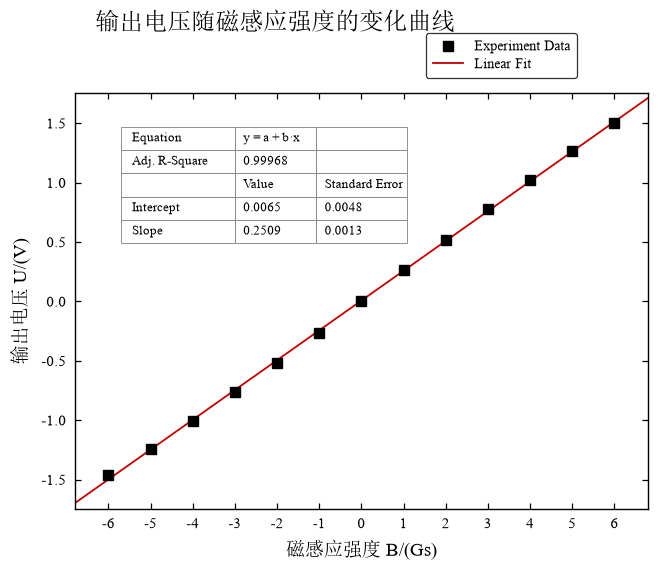

In [2]:
# ================= 图 1：散点 + 线性拟合（Origin 版式） =================
fig, ax = plt.subplots(figsize=(7.4, 5.4))

# 实验点（黑色实心方块）
# 图例文字用英文：中文标签在内联预览的图例里可能丢字（不影响存图）
ax.plot(B_Gs, U_V, linestyle='none', marker='s', markersize=6.5,
        color='black', label='Experiment Data', zorder=3)

# 拟合直线（注意：只画直线，不连数据点）
xx = np.linspace(-6.8, 6.8, 200)
ax.plot(xx, a + b * xx, color='#C00000', linewidth=1.3,
        label='Linear Fit', zorder=2)

style_axes(ax)
ax.set_title('输出电压随磁感应强度的变化曲线', fontsize=17, x=0.35, pad=46)

leg = ax.legend(loc='lower left', bbox_to_anchor=(0.60, 1.02),
                fontsize=10, frameon=True, borderpad=0.5,
                labelspacing=0.35, handlelength=2.2)
leg.get_frame().set_linewidth(0.9)
leg.get_frame().set_edgecolor('black')

# ---- Origin 风格拟合结果框 ----
add_table_box(ax,
              rows=[['Equation',      'y = a + b·x',   ''],
                    ['Adj. R-Square', f'{adj_r2:.5f}', ''],
                    ['',              'Value',         'Standard Error'],
                    ['Intercept',     f'{a:.4f}',      f'{se_a:.4f}'],
                    ['Slope',         f'{b:.4f}',      f'{se_b:.4f}']],
              col_widths=[0.40, 0.28, 0.32],
              bbox=[0.08, 0.64, 0.50, 0.28])

plt.savefig('图1_磁阻传感器_磁电转换特性_线性拟合.png', dpi=300, bbox_inches='tight')
plt.show()


## 结果分析

**1. 线性关系成立，得到磁电转换灵敏度**

拟合得
$$U = (0.0065 \pm 0.0048)\ \mathrm{V} + (0.2509 \pm 0.0013)\ \mathrm{V/Gs}\cdot B,$$
$\mathrm{Adj.}\ R^2 = 0.99968$，Pearson 相关系数 $r = 0.99985$，残差平方和仅 $3.3\times10^{-3}\ \mathrm{V^2}$。
在 $B=-6\sim6$ Gs 范围内输出电压与磁感应强度高度线性，说明磁阻传感器处于其线性工作区。

- 灵敏度 $K = b = 0.2509\ \mathrm{V/Gs} = 2.51\times10^3\ \mathrm{V/T} \approx 250.9\ \mathrm{mV/Gs}$。
  按地磁场水平分量 0.3–0.6 Gs 估算，传感器输出约 0.08–0.15 V，与后续测量所需的信号量级相符。
- 零点残余 $U_0 \approx 6.5$ mV（$B=0$ 时实测 2 mV）。截距与 0 相差约 1.3 个标准误差，
  在 95% 置信度下不显著偏离 0，说明零点失调很小。

**2. 线性度与系统不对称**

- 最大残差出现在 $B=-6$ Gs：实测 $-1.464$ V，拟合值 $-1.499$ V，偏差 $+0.035$ V；
  相对满量程 2.964 V 的线性度误差约为 **1.2% FS**。
- 正、负半轴分别拟合，灵敏度为 0.2504 与 0.2445 V/Gs，相差约 2.4%；
  $U(+B)+U(-B)$ 随 $|B|$ 从 $-0.002$ V 单调增大到 $0.036$ V，
  即正向读数系统性略大于反向读数。**这是原始数据本身的性质，图中未作任何修正。**
- 造成不对称的可能原因：磁阻传感器的磁滞（置位/复位脉冲未完全消除历史磁化）、
  螺线管正反向电流产生的磁场不完全对称、电流/电压表读数与零点漂移。
  后续测量地磁场时可用**正反向读数相减**（翻转法）消除这一项。

**3. 结论**

表 11-1 的数据在 $-6\sim6$ Gs 内满足 $U=K B+U_0$，$K \approx 0.251$ V/Gs，
$\mathrm{Adj.}\ R^2 > 0.999$，线性度误差约 1.2%，该传感器可直接用于地磁场（0.3–0.6 Gs 量级）的测量；
测量时应采用翻转法扣除零点残余与正反向不对称。
